# SLAP-GRO: Storage Location Assignment Problem (SLAP)

Notebook này phân tích và trực quan hóa 4 chính sách lưu trữ vị trí hàng hóa trong kho:
1. **Random Storage**: Phân bổ ngẫu nhiên không phân biệt mức độ ưu tiên.
2. **Class-Based Storage**: Phân bổ theo 3 vùng $Z_A < Z_B < Z_C$ dựa trên khoảng cách tới Depot.
3. **Dedicated Storage**: Sắp xếp cố định theo thứ hạng tần suất nhu cầu (demand frequency ranking).
4. **Hybrid Storage**: 20% SKU nhóm A cố định gần Depot, 80% nhóm B và C phân bổ ngẫu nhiên có kiểm soát.


In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project path setup
project_root = Path(os.getcwd()).resolve().parent if 'notebooks' in os.getcwd() else Path(os.getcwd()).resolve()
sys.path.insert(0, str(project_root / 'src'))

from slap_gro.data.loaders import load_storage_matrix, load_storage_locations
from slap_gro.storage import get_storage_policy, StorageMatrix
from slap_gro.warehouse import build_warehouse
from slap_gro.routing.distance import distance

# Nạp mô hình kho thực tế và Depot
wh = build_warehouse('real')
depot = wh.get_depot()
print(f'Warehouse loaded: {wh.total_locations} locations, Depot at ({depot.x}, {depot.y}, {depot.z})')


Warehouse loaded: 2292 locations, Depot at (0.0, 0.0, 1.0)


In [1]:
# Nạp 4 ma trận lưu trữ thực tế từ CSV
policies = ['random', 'class_based', 'dedicated', 'hybrid']
summary = []

for p in policies:
    policy_obj = get_storage_policy(p, source='observed')
    matrix = policy_obj.matrix
    occupied = sum(u.occupied_slots_count for u in matrix.units.values())
    skus = matrix.unique_skus
    summary.append({
        'Policy': p.upper(),
        'Units': len(matrix.location_ids),
        'Total Slots': len(matrix.location_ids) * 18,
        'Occupied Slots': occupied,
        'Utilization Rate (%)': round(occupied / (len(matrix.location_ids) * 18) * 100, 2),
        'Unique SKUs': len(skus),
    })

df_summary = pd.DataFrame(summary)
display(df_summary) if 'display' in globals() else print(df_summary.to_string(index=False))


     Policy  Units  Total Slots  Occupied Slots  Utilization Rate (%)  Unique SKUs
     RANDOM   2292        41256           41256                 100.0          208
CLASS_BASED   2341        42138           42138                 100.0          317
  DEDICATED   2340        42120           42120                 100.0          208
     HYBRID   2340        42120           42120                 100.0          208


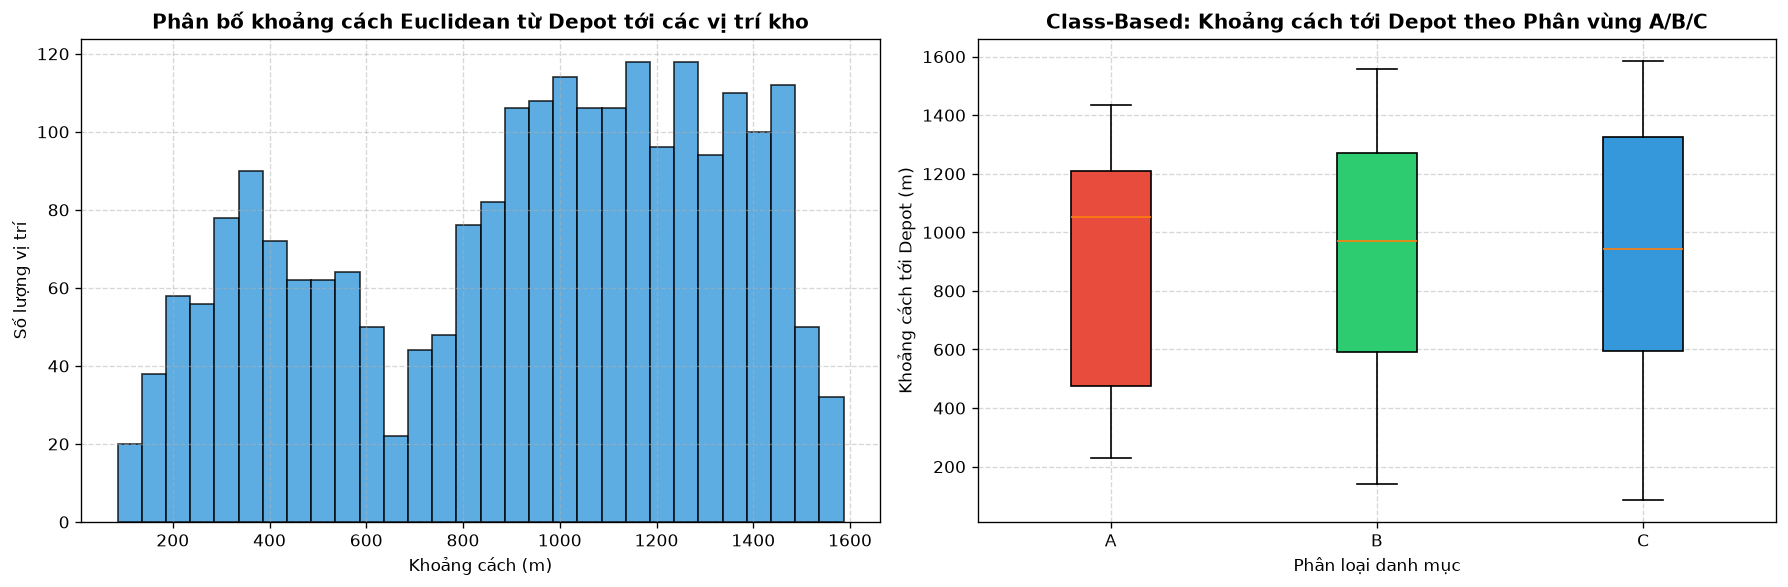

In [1]:
# Phân tích khoảng cách từ Depot tới các vị trí lưu trữ Class A, B, C
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Histogram khoảng cách từ Depot của toàn bộ vị trí kho
distances = [distance(wh.get_depot(), loc, method='euclidean') for loc in wh.get_all_locations()]
axes[0].hist(distances, bins=30, color='#3498db', edgecolor='black', alpha=0.8)
axes[0].set_title('Phân bố khoảng cách Euclidean từ Depot tới các vị trí kho', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Khoảng cách (m)')
axes[0].set_ylabel('Số lượng vị trí')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. So sánh Class-Based Storage: Khoảng cách các vùng ABC
cb_policy = get_storage_policy('class_based', source='observed')
cb_mat = cb_policy.matrix
cat_data = []
for loc_id, unit in cb_mat.units.items():
    loc = wh.get_location(loc_id)
    if loc and unit.category_code:
        d = distance(wh.get_depot(), loc, method='euclidean')
        cat_data.append({'Category': unit.category_code, 'Distance': d})

df_cat = pd.DataFrame(cat_data)
df_cat_sorted = df_cat.sort_values('Category')
box_colors = {'A': '#e74c3c', 'B': '#2ecc71', 'C': '#3498db'}
categories = sorted(df_cat['Category'].dropna().unique())
box_plot_data = [df_cat[df_cat['Category'] == c]['Distance'].values for c in categories]

bplot = axes[1].boxplot(box_plot_data, tick_labels=categories, patch_artist=True)
for patch, cat in zip(bplot['boxes'], categories):
    patch.set_facecolor(box_colors.get(cat, '#95a5a6'))
axes[1].set_title('Class-Based: Khoảng cách tới Depot theo Phân vùng A/B/C', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Phân loại danh mục')
axes[1].set_ylabel('Khoảng cách tới Depot (m)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


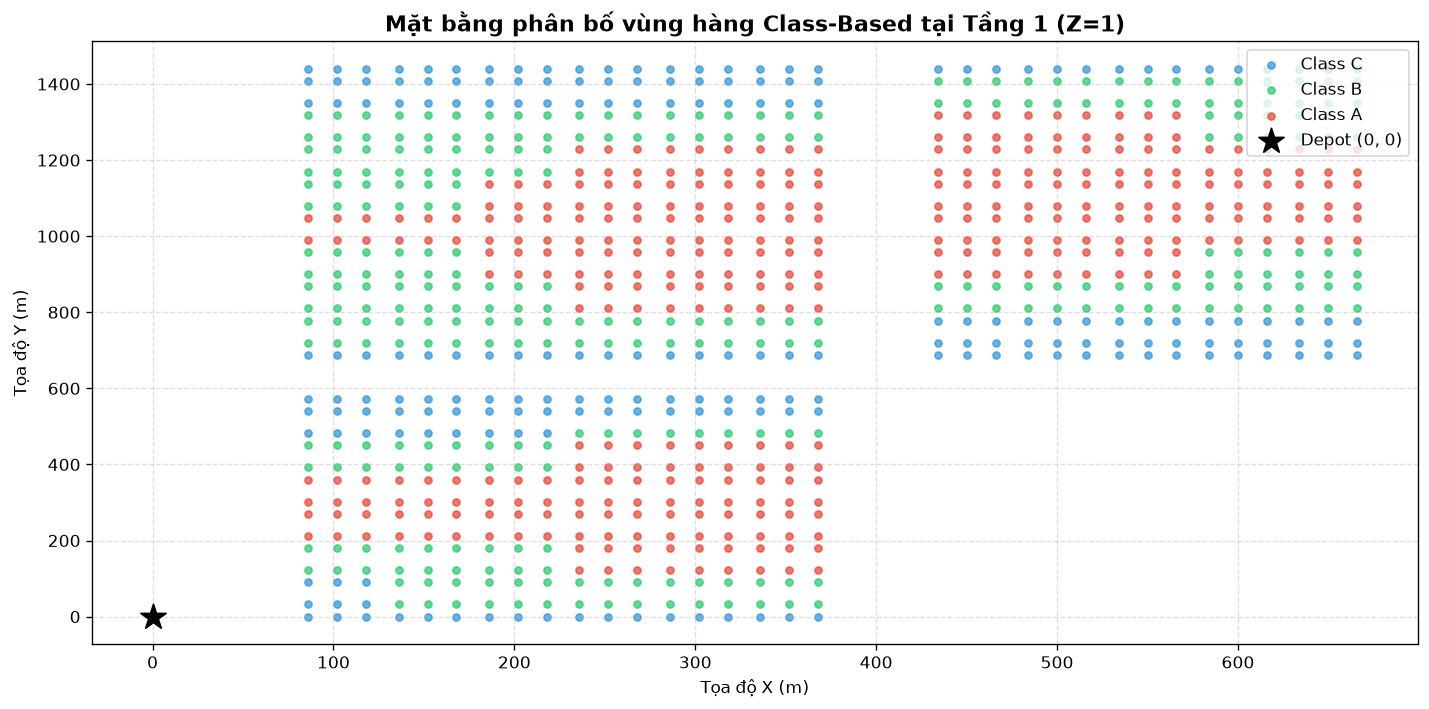

In [1]:
# Trực quan hóa mặt bằng kho 2D phân bố phân vùng A/B/C trên tầng 1 (Z=1)
fig, ax = plt.subplots(figsize=(12, 6))
color_map = {'A': '#e74c3c', 'B': '#2ecc71', 'C': '#3498db'}

for cat in ['C', 'B', 'A']:  # Vẽ A lên trên cùng
    xs, ys = [], []
    for loc_id, unit in cb_mat.units.items():
        loc = wh.get_location(loc_id)
        if loc and loc.z == 1 and unit.category_code == cat:
            xs.append(loc.x)
            ys.append(loc.y)
    ax.scatter(xs, ys, c=color_map.get(cat, '#bdc3c7'), label=f'Class {cat}', s=18, alpha=0.75)

ax.scatter([depot.x], [depot.y], c='black', marker='*', s=250, label='Depot (0, 0)', zorder=5)
ax.set_title('Mặt bằng phân bố vùng hàng Class-Based tại Tầng 1 (Z=1)', fontsize=13, fontweight='bold')
ax.set_xlabel('Tọa độ X (m)')
ax.set_ylabel('Tọa độ Y (m)')
ax.legend(loc='upper right', frameon=True)
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
